# 02 · Results

Validation (2022–2024) and the single locked run on 2025. This notebook fits nothing:
it reads what `make cv` and `make test-2025` saved under `reports/` and displays it.
Run it with `make report`.

In [1]:
import sys

sys.path.insert(0, "../src")  # works without `pip install -e .`

import json

import pandas as pd
from IPython.display import Image, Markdown, display

from f1pred import evaluate as ev
from f1pred.config import FIGURES, FROZEN_CONFIG, REPORTS
from f1pred.metrics import calibration_table

config = json.loads(FROZEN_CONFIG.read_text())
cv = ev.split_models(pd.read_csv(REPORTS / "cv" / "predictions.csv"))
test = ev.split_models(pd.read_csv(REPORTS / "test_2025" / "predictions.csv"))
metrics = json.loads((REPORTS / "test_2025" / "metrics.json").read_text())
show = lambda df: display(df.style.hide(axis="index"))
print(f"frozen {config['frozen_at']}: {len(config['features'])} features, "
      f"2025 run {metrics['run_at']} at tag {metrics['tag']} ({metrics['tag_commit'][:7]})")

frozen 2026-10-12T16:23:24+00:00: 14 features, 2025 run 2026-10-12T16:23:52+00:00 at tag v1.0 (671bd10)


## The frozen model

In [2]:
print(config["features"])
print({k: config["params"][k] for k in ("max_depth", "learning_rate", "n_estimators", "min_child_weight")},
      "| recency weighting:", config["recency_decay"], "| seeds:", config["seeds"])

['grid_pos', 'quali_pos', 'quali_gap_pct', 'teammate_quali_delta', 'longrun_gap_pct', 'shortrun_gap_pct', 'has_longrun', 'sprint_pos', 'drv_avg_finish_5', 'drv_wins_5', 'drv_podiums_5', 'team_points_5', 'champ_rank', 'dnf_rate_10']
{'max_depth': 2, 'learning_rate': 0.03, 'n_estimators': 400, 'min_child_weight': 5} | recency weighting: None | seeds: [0, 1, 2, 3, 4]


## Walk-forward validation, 2022–2024

Each season is predicted by a model trained on all earlier seasons.

In [3]:
show(ev.results_table(cv))

Model,Picked the winner,95% CI,vs pole sitter (95% CI),Winner in top 3,Hits when pole lost,Log loss,Brier
XGBoost,39 of 68 (57.4%),45.5% to 68.4%,+5.9% (-4.4% to +16.2%),60 of 68 (78.5% to 93.9%),9 of 33,0.0964,0.0290
Pole sitter,35 of 68 (51.5%),39.8% to 62.9%,baseline,57 of 68 (73.3% to 90.7%),0 of 33,n/a,n/a
Form leader,35 of 68 (51.5%),39.8% to 62.9%,+0.0% (-16.2% to +16.2%),48 of 68 (58.9% to 80.1%),16 of 33,n/a,n/a
Grid-only logistic regression,34 of 68 (50.0%),38.4% to 61.6%,-1.5% (-4.4% to +0.0%),58 of 68 (75.0% to 91.8%),0 of 33,0.1247,0.0346


In [4]:
folds = pd.read_csv(REPORTS / "cv" / "results.csv")
show(folds[folds["season"] != "pooled"].round(4))

model,season,races,winner_hit,top3_hit,pole_lost_races,hit_when_pole_lost,log_loss,brier
Pole sitter,2022,22,0.454500,0.818200,12,0.000000,nan,nan
Pole sitter,2023,22,0.636400,0.863600,8,0.000000,nan,nan
Pole sitter,2024,24,0.458300,0.833300,13,0.000000,nan,nan
Form leader,2022,22,0.500000,0.636400,12,0.500000,nan,nan
Form leader,2023,22,0.863600,0.954500,8,0.875000,nan,nan
Form leader,2024,24,0.208300,0.541700,13,0.230800,nan,nan
Grid-only logistic regression,2022,22,0.409100,0.818200,12,0.000000,0.129300,0.037100
Grid-only logistic regression,2023,22,0.636400,0.909100,8,0.000000,0.106300,0.031100
Grid-only logistic regression,2024,24,0.458300,0.833300,13,0.000000,0.137300,0.035600
XGBoost,2022,22,0.409100,0.909100,12,0.083300,0.109200,0.035100


### Ablation: feature groups added one at a time

step,features,winner_hit,top3_hit,hit_when_pole_lost,log_loss,brier,log_loss_2022,log_loss_2023,log_loss_2024
grid only,4,0.514700,0.852900,0.060600,0.115100,0.034900,0.127600,0.095400,0.121800
+ practice,7,0.485300,0.852900,0.151500,0.114500,0.034500,0.121100,0.097200,0.124200
+ sprint,8,0.485300,0.852900,0.181800,0.114800,0.034600,0.121600,0.097000,0.125100
+ form,14,0.558800,0.882400,0.242400,0.097500,0.029400,0.110800,0.059500,0.120300
+ circuit,17,0.573500,0.882400,0.242400,0.098500,0.029600,0.113700,0.060900,0.119100
+ weather,19,0.573500,0.867600,0.242400,0.098600,0.029400,0.114000,0.061300,0.118600


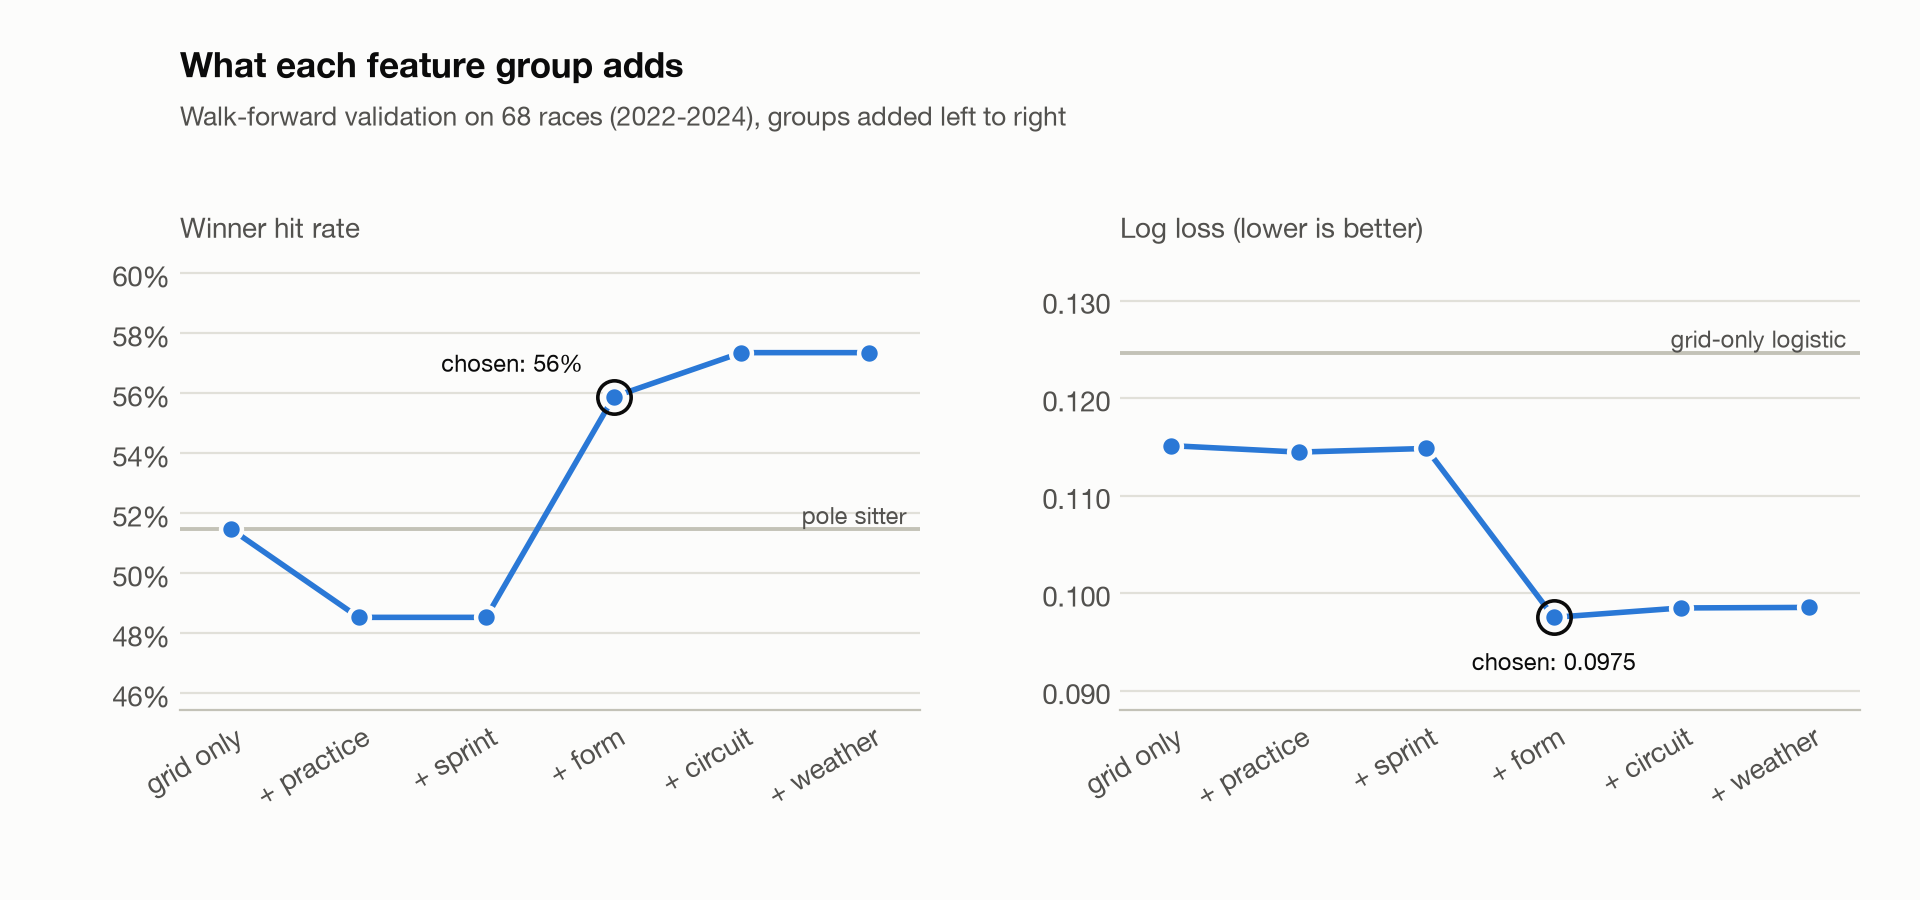

In [5]:
show(pd.read_csv(REPORTS / "cv" / "ablation.csv").round(4))
display(Image(filename=str(FIGURES / "ablation.png"), width=860))

### Recency weighting and the parameter grid

In [6]:
show(pd.read_csv(REPORTS / "cv" / "recency.csv").round(4))
show(pd.read_csv(REPORTS / "cv" / "grid.csv").head(10).round(4))

weighting,winner_hit,top3_hit,hit_when_pole_lost,log_loss,brier,log_loss_2022,log_loss_2023,log_loss_2024
equal,0.573500,0.882400,0.272700,0.096400,0.029000,0.109200,0.057900,0.119900
0.7 ** seasons back,0.529400,0.882400,0.242400,0.097700,0.028800,0.109500,0.054500,0.126700


max_depth,learning_rate,n_estimators,min_child_weight,winner_hit,top3_hit,hit_when_pole_lost,log_loss,brier,log_loss_2022,log_loss_2023,log_loss_2024
2,0.030000,400,5,0.573500,0.882400,0.272700,0.096400,0.029000,0.109200,0.057900,0.119900
2,0.030000,200,5,0.558800,0.882400,0.303000,0.096400,0.028700,0.109400,0.057300,0.120300
2,0.030000,200,10,0.602900,0.911800,0.363600,0.096400,0.028300,0.110000,0.056800,0.120300
3,0.030000,200,10,0.602900,0.911800,0.363600,0.096500,0.028400,0.109900,0.057200,0.120200
4,0.030000,200,10,0.602900,0.911800,0.363600,0.096500,0.028400,0.109900,0.057200,0.120200
3,0.030000,200,5,0.558800,0.882400,0.303000,0.097100,0.029000,0.110100,0.058800,0.120300
2,0.100000,200,5,0.529400,0.867600,0.212100,0.097400,0.029300,0.110500,0.058600,0.121100
4,0.030000,200,5,0.544100,0.897100,0.272700,0.097500,0.029100,0.110200,0.059300,0.121000
4,0.030000,400,10,0.588200,0.897100,0.333300,0.097500,0.029000,0.111000,0.058000,0.121400
3,0.030000,400,10,0.588200,0.897100,0.333300,0.097500,0.029000,0.111000,0.058000,0.121400


### Calibration on the validation folds

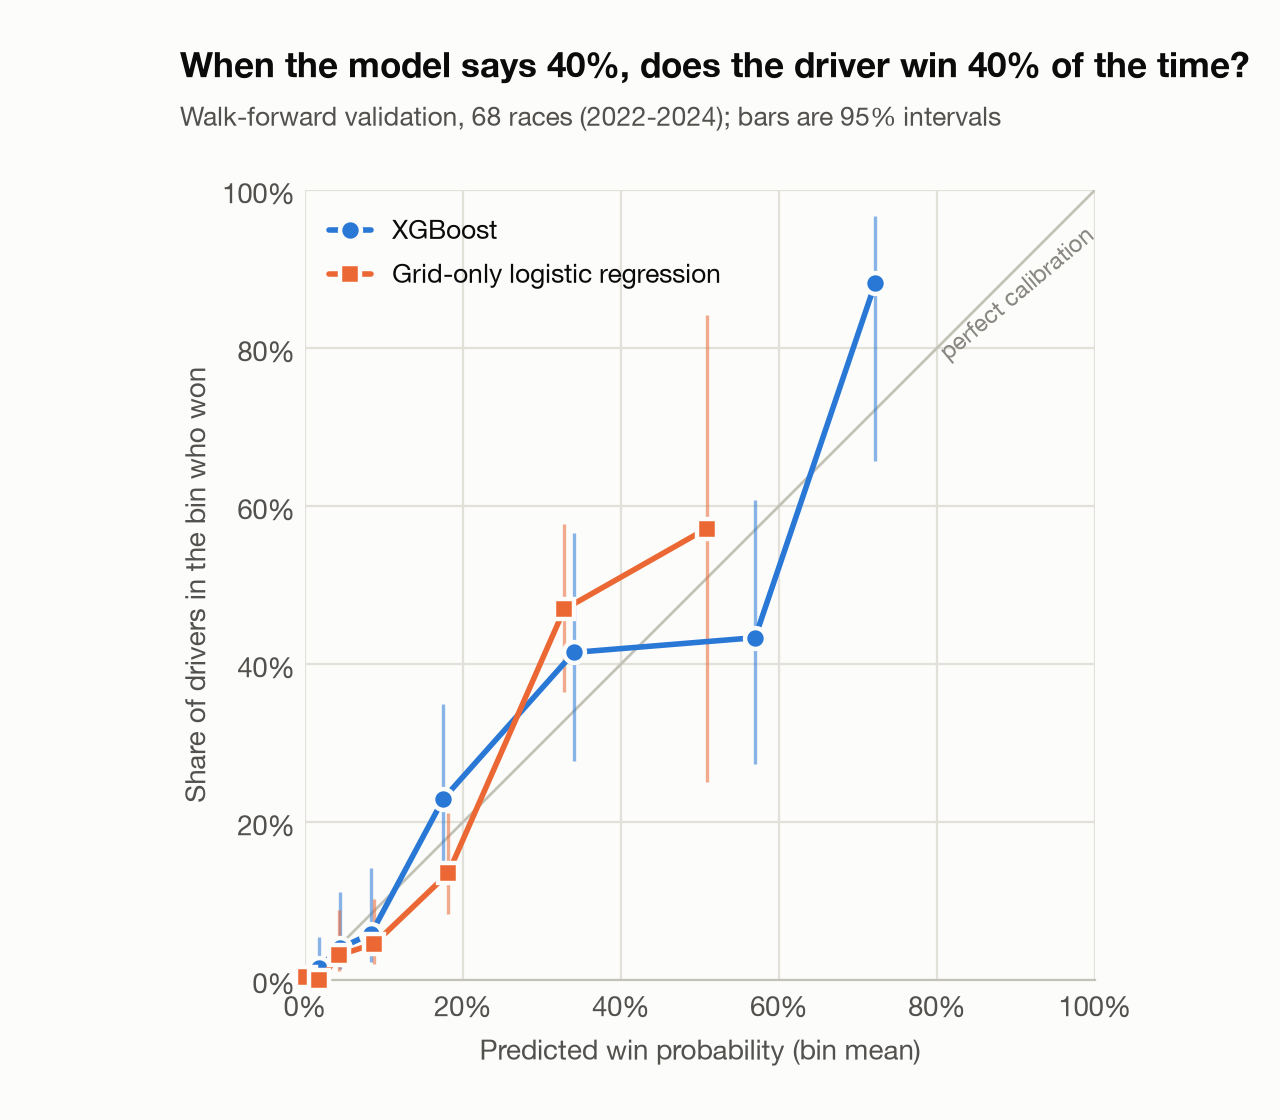

bin,predicted,observed,wins,rows
"(-0.001, 0.01]",0.003000,0.000000,0,936
"(0.01, 0.03]",0.017000,0.015000,2,131
"(0.03, 0.06]",0.044000,0.040000,3,75
"(0.06, 0.12]",0.084000,0.059000,4,68
"(0.12, 0.25]",0.175000,0.230000,14,61
"(0.25, 0.45]",0.340000,0.415000,17,41
"(0.45, 0.65]",0.570000,0.433000,13,30
"(0.65, 1.0]",0.722000,0.882000,15,17


In [7]:
display(Image(filename=str(FIGURES / "calibration_validation.png"), width=620))
show(calibration_table(cv[ev.MODEL_NAME]).assign(bin=lambda t: t["bin"].astype(str)).round(3))

## The locked 2025 test

Trained on 2019–2024 with the frozen setup, run once.

In [8]:
show(ev.results_table(test))
v = metrics["log_loss_vs_logreg"]
Markdown(f"Log loss against the grid-only logistic regression: {v['diff']:+.4f} ({v['relative']:+.1%}; "
         f"95% CI {v['lo']:+.4f} to {v['hi']:+.4f}).")

Model,Picked the winner,95% CI,vs pole sitter (95% CI),Winner in top 3,Hits when pole lost,Log loss,Brier
XGBoost,15 of 24 (62.5%),42.7% to 78.8%,-4.2% (-20.8% to +12.5%),24 of 24 (86.2% to 100.0%),2 of 8,0.0895,0.0285
Pole sitter,16 of 24 (66.7%),46.7% to 82.0%,baseline,23 of 24 (79.8% to 99.3%),0 of 8,n/a,n/a
Form leader,7 of 24 (29.2%),14.9% to 49.2%,-37.5% (-62.5% to -8.3%),17 of 24 (50.8% to 85.1%),3 of 8,n/a,n/a
Grid-only logistic regression,16 of 24 (66.7%),46.7% to 82.0%,same hits and misses,23 of 24 (79.8% to 99.3%),0 of 8,0.0985,0.0299


Log loss against the grid-only logistic regression: -0.0090 (-9.2%; 95% CI -0.0221 to +0.0053).

### Race by race

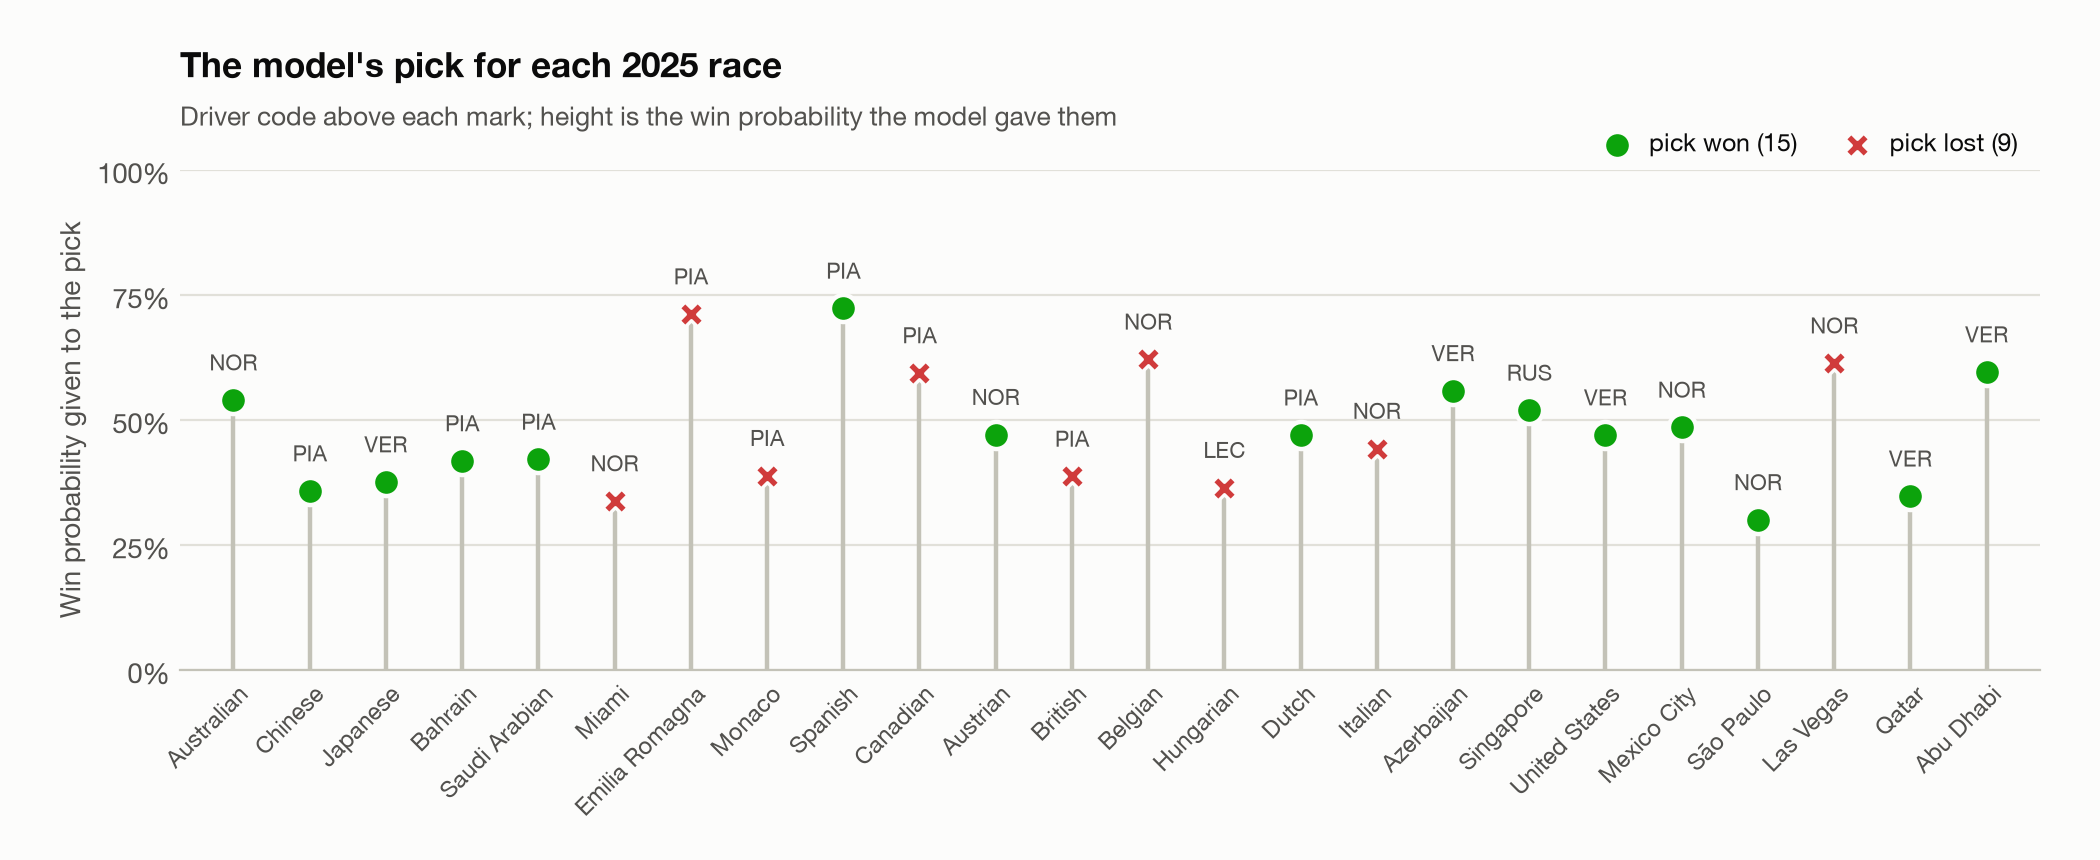

round,label,winner,pick,pick_p,pole,hit,winner_p,winner_rank,reasons,cause
1,Australian,NOR,NOR,0.540000,NOR,1,0.540000,1,"starting position, qualifying position",
2,Chinese,PIA,PIA,0.358000,PIA,1,0.358000,1,"starting position, qualifying position",
3,Japanese,VER,VER,0.376000,VER,1,0.376000,1,"starting position, qualifying position",
4,Bahrain,PIA,PIA,0.418000,PIA,1,0.418000,1,"starting position, qualifying position",
5,Saudi Arabian,PIA,PIA,0.421000,VER,1,0.421000,1,"starting position, qualifying gap to pole",
6,Miami,PIA,NOR,0.338000,VER,0,0.317000,2,"starting position, recent finishes",Race incident
7,Emilia Romagna,VER,PIA,0.712000,PIA,0,0.088000,3,"recent wins, starting position",Pace misread
8,Monaco,NOR,PIA,0.389000,NOR,0,0.386000,2,"recent wins, recent finishes",Pace misread
9,Spanish,PIA,PIA,0.723000,PIA,1,0.723000,1,"recent wins, starting position",
10,Canadian,RUS,PIA,0.594000,RUS,0,0.239000,2,"recent wins, qualifying gap to pole",Pace misread


In [9]:
display(Image(filename=str(FIGURES / "race_strip_2025.png"), width=980))
races = pd.read_csv(REPORTS / "test_2025" / "per_race.csv")
show(races[["round", "label", "winner", "pick", "pick_p", "pole", "hit", "winner_p", "winner_rank",
            "reasons", "cause"]].fillna("").round(3))

### What the model relies on

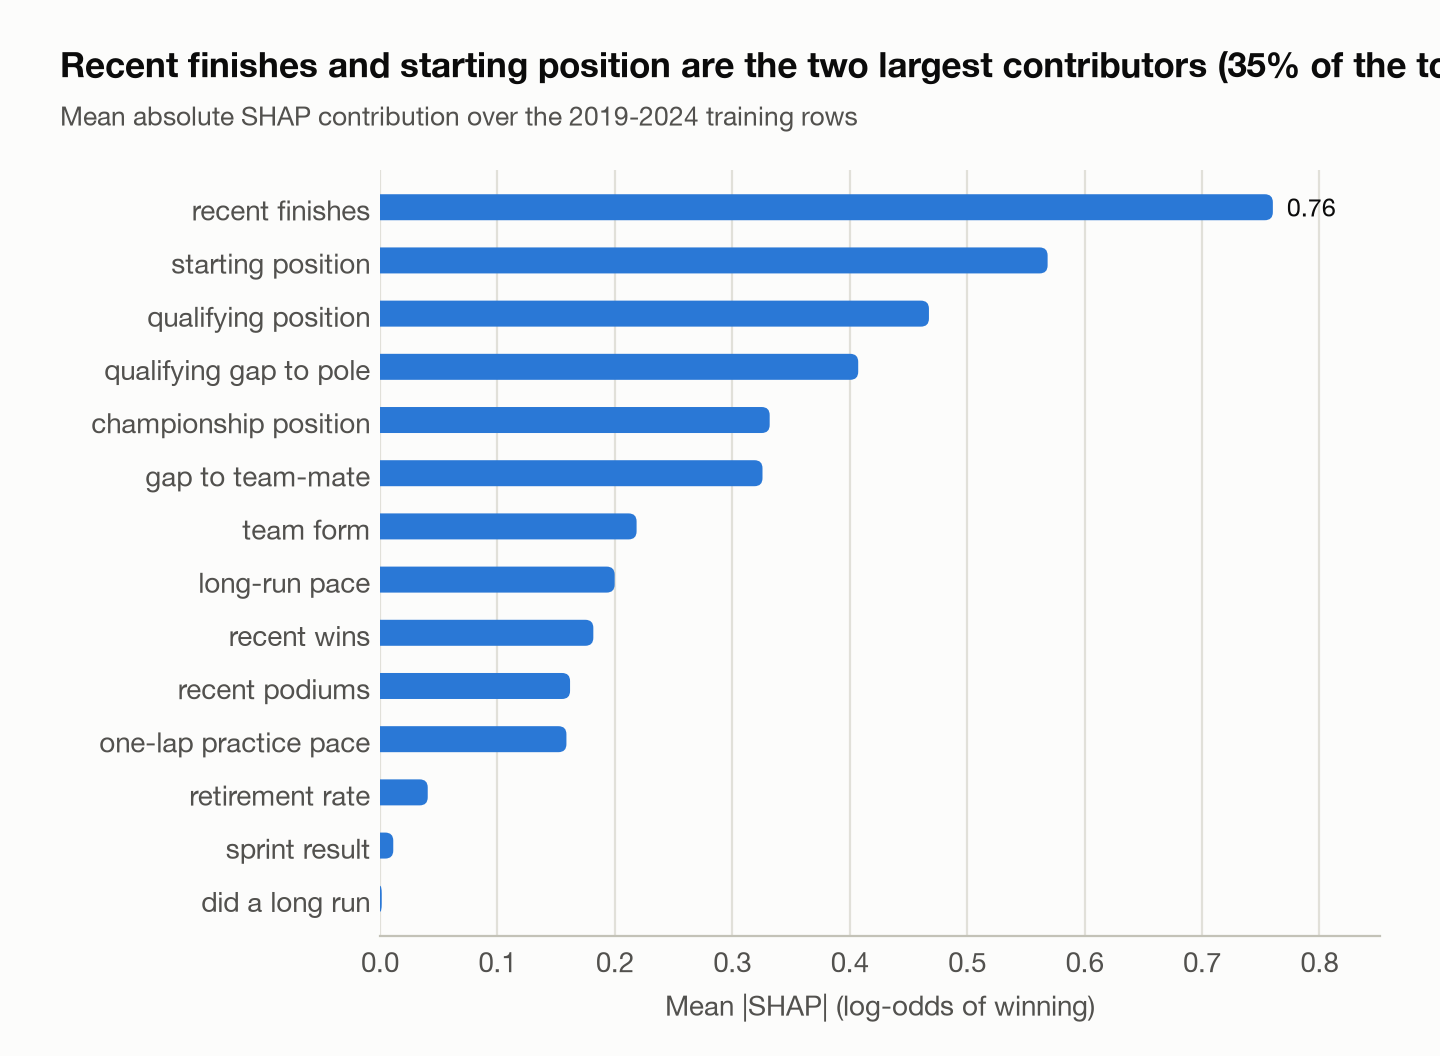

In [10]:
display(Image(filename=str(FIGURES / "feature_importance.png"), width=700))

### 2025 calibration (24 races, so the bins are thin)

In [11]:
show(calibration_table(test[ev.MODEL_NAME]).assign(bin=lambda t: t["bin"].astype(str)).round(3))

bin,predicted,observed,wins,rows
"(-0.001, 0.01]",0.002000,0.000000,0,343
"(0.01, 0.03]",0.018000,0.000000,0,28
"(0.03, 0.06]",0.042000,0.000000,0,27
"(0.06, 0.12]",0.085000,0.062000,1,16
"(0.12, 0.25]",0.176000,0.103000,3,29
"(0.25, 0.45]",0.343000,0.478000,11,23
"(0.45, 0.65]",0.540000,0.727000,8,11
"(0.65, 1.0]",0.717000,0.500000,1,2
